# Opal multiplex IF – TMA analysis, one assay at a time

This notebook walks through the project's cell-analysis pipeline (the `analyzing-qupath-cells` skill,
`.claude/skills/analyzing-qupath-cells/`) step by step on **a single assay**, explaining each decision.

**How the data is organised**

- Each TMA slide was scanned on the Polaris and segmented in QuPath. One export file per TMA:
  `Cell_dectection_results/YYYYMMDD_cell_detection_TMA<n>.txt` (tab-separated, one row per cell).
- **A TMA holds many small assays** (tissue cores). The assay each cell belongs to is in the **`Parent`**
  column (e.g. `COL-502BG`).
- Each cell has a centroid (`Centroid X µm`, `Centroid Y µm`), morphology (area, perimeter, …) and, per
  marker, the mean intensity in the nucleus, cytoplasm and whole cell (`Cell: p62 (Opal 520) mean`, …).

**Pipeline**

| Step | What | Why |
|---|---|---|
| 1 | Load one TMA, pick one assay | assays are small; start with one to tune settings |
| 2 | Find marker columns | build the panel from the column names |
| 3 | Quality control | remove missing values, too small / too big cells, low-DAPI cells, cells with no signal |
| 4 | Spatial intensity maps | sanity-check staining on the tissue |
| 5 | Build AnnData | standard container for scanpy / squidpy |
| 6 | Clip very bright cells | stop a few extreme cells from driving the analysis; chosen per marker |
| 7 | Transform | `log1p` (+ optional z-scoring) |
| 8 | Cluster | PCA → neighbours → UMAP → Leiden, dotplot / matrixplot |
| 9 | Clusters on tissue + neighbourhood enrichment | spatial organisation of cell groups |
| 10 | Save, then scale up to all assays | |

Kernel: **conver-cell-detection** (the project's uv `.venv`).

## 0. Setup

In [1]:
import re
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

sc.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_columns", 50)

X_COL, Y_COL = "Centroid X µm", "Centroid Y µm"
AREA_COL = "Cell: Area"


def tissue_scatter(ax, xy, c, title="", **kw):
    """Cells at their centroid positions. Image y grows downwards, so the y axis is inverted."""
    s = ax.scatter(xy[:, 0], xy[:, 1], c=c, s=2, rasterized=True, **kw)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xlabel("X µm")
    ax.set_ylabel("Y µm")
    return s

/Users/comeara/GitRepos/Conver_cell_detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Parameters

Everything you are likely to change lives here. Defaults match the skill's `run_pipeline.py`
(QC values follow `tma_exploration` / the IMC example `0921_scRNA_IMC.ipynb`). Clip levels are set
later, in step 6, after looking at the histograms.

In [2]:
TMA_FILE = Path("Cell_dectection_results/20260918_cell_detection_TMA1.txt")
ASSAY = "COL-502BG"                 # one assay (core) on this TMA – the IDs are in `Parent`

NUCLEAR_MARKER = "DAPI"             # kept for QC, left out of clustering
EXCLUDE = ["AF", "Autofluorescence"]  # channels never analysed

# quality control (quantiles are computed within the assay)
AREA_QUANTILES = (0.01, 0.99)       # keep cells whose area is inside these quantiles (IMC example: 0.05, 0.95)
MIN_NUCLEAR_QUANTILE = 0.01         # drop the dimmest 1 % of nuclei
SIGNAL_QUANTILE = 0.10              # a marker is "expressed" when above this quantile (background)
MIN_MARKERS = 1                     # drop cells expressing fewer panel markers than this (IMC example: 2)
MAX_AF_QUANTILE = None              # e.g. 0.99 to drop very autofluorescent cells (RBCs, necrosis)

# clustering
SCALE = True                        # z-score markers before PCA so bright channels don't dominate
N_NEIGHBORS, N_PCS = 15, 5
RESOLUTION = 0.5                    # Leiden resolution; higher = more, smaller clusters

OUT_DIR = Path("results/assays")

## 1. Load one TMA and choose an assay

The export holds every cell on the slide. Count cells per assay first: very small assays
(damaged or mostly lost cores) give unreliable results and are poor choices for tuning settings.

20260918_cell_detection_TMA1.txt: 80,922 cells in 15 assays


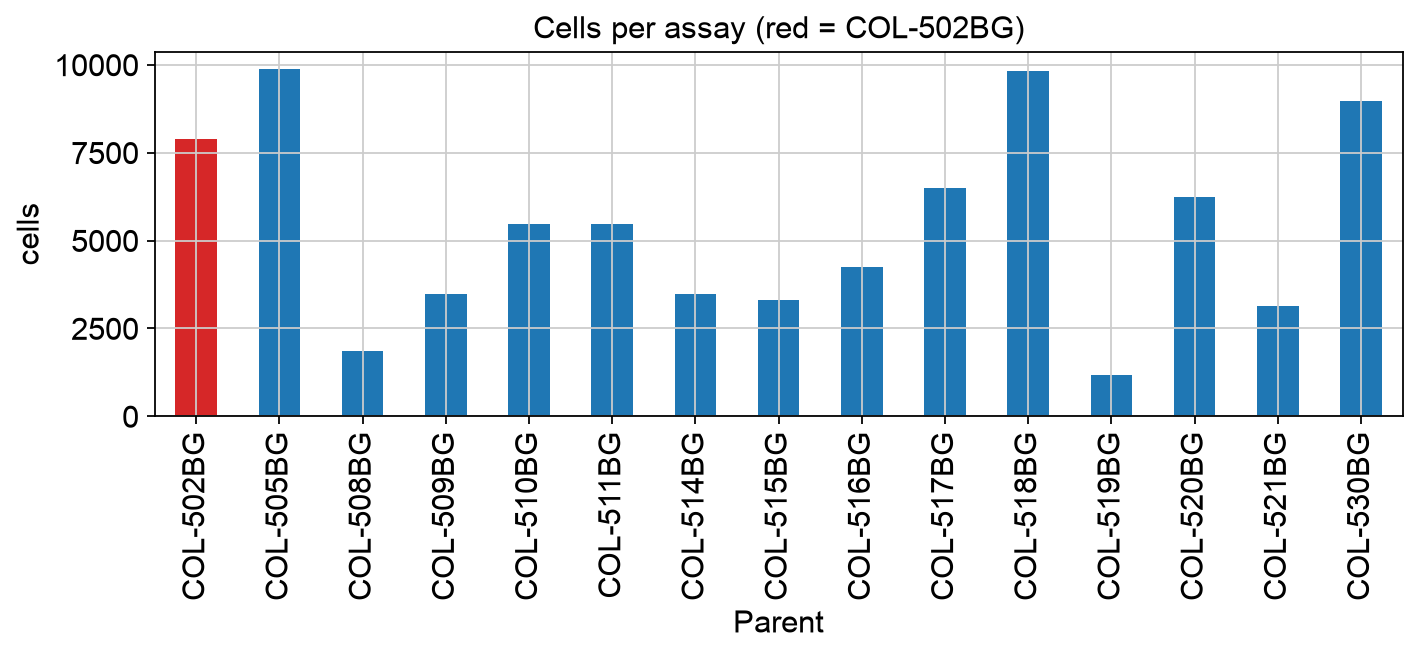

In [3]:
raw_tma = pd.read_csv(TMA_FILE, sep="\t", low_memory=False)
assay_counts = raw_tma["Parent"].value_counts().sort_index()
print(f"{TMA_FILE.name}: {len(raw_tma):,} cells in {len(assay_counts)} assays")

fig, ax = plt.subplots(figsize=(10, 3))
assay_counts.plot.bar(ax=ax, color=["tab:red" if a == ASSAY else "tab:blue" for a in assay_counts.index])
ax.set_ylabel("cells")
ax.set_title(f"Cells per assay (red = {ASSAY})")
plt.show()

The assays sit side by side on the slide. Plotting all centroids shows the TMA layout; the chosen
assay is highlighted.

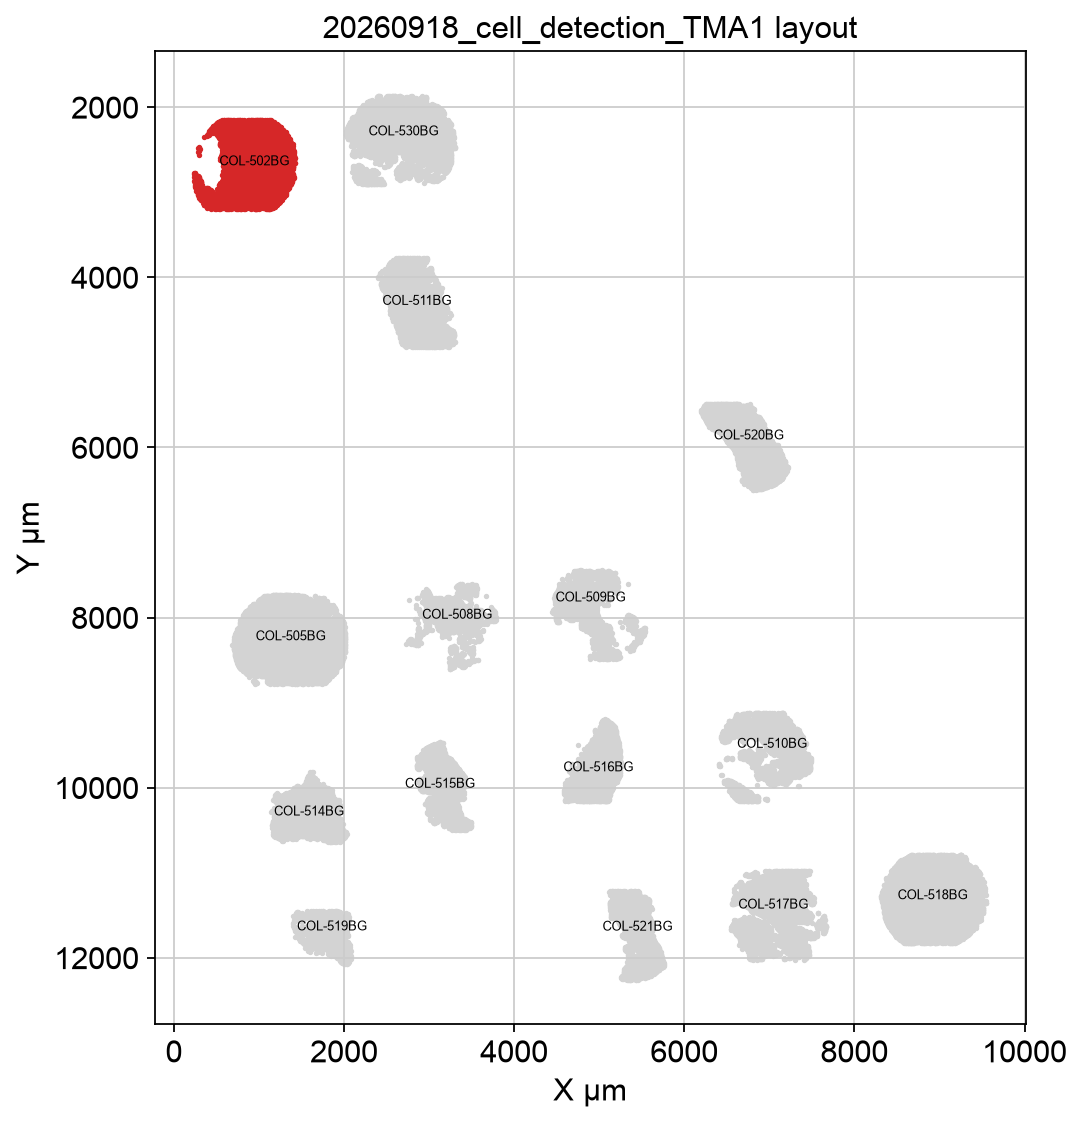

COL-502BG: 7,881 cells


In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
is_assay = (raw_tma["Parent"] == ASSAY).to_numpy()
xy = raw_tma[[X_COL, Y_COL]].to_numpy()
tissue_scatter(ax, xy[~is_assay], "lightgrey", f"{TMA_FILE.stem} layout")
ax.scatter(*xy[is_assay].T, s=2, c="tab:red", rasterized=True)
for name, pos in raw_tma.groupby("Parent")[[X_COL, Y_COL]].median().iterrows():
    ax.annotate(name, pos, fontsize=6, ha="center")
plt.show()

raw = raw_tma[raw_tma["Parent"] == ASSAY].reset_index(drop=True)
print(f"{ASSAY}: {len(raw):,} cells")

## 2. Find the marker columns

QuPath names whole-cell mean intensities `Cell: <marker> (<fluorophore>) mean`. DAPI and
autofluorescence have no fluorophore suffix (`Cell: DAPI mean`). The regular expression below takes the
text before ` (` as the marker name, so both forms work, and the panel is built from the file itself.

In [5]:
MEAN_RE = re.compile(r"^Cell: (?P<marker>[^(]+?)(?: \(.*\))? mean$")
all_means = {m.group("marker"): c for c in raw.columns if (m := MEAN_RE.match(c))}
cols = {m: c for m, c in all_means.items() if m not in EXCLUDE}   # marker -> column
markers = list(cols)
panel = [m for m in markers if m != NUCLEAR_MARKER]               # markers used for clustering
AF_COL = next((all_means[n] for n in EXCLUDE if n in all_means), None)

print("markers:", markers)
print("clustering panel:", panel)
raw[list(all_means.values())].describe().T.round(3)

markers: ['p62', 'CD147', 'LC3AB', 'Hpyl', 'MCT4', 'MCT1', 'HCAR1', 'DAPI']
clustering panel: ['p62', 'CD147', 'LC3AB', 'Hpyl', 'MCT4', 'MCT1', 'HCAR1']


,count,mean,std,min,25%,50%,75%,max
Cell: p62 (Opal 520) mean,7881.0,1.693,0.967,0.161,1.156,1.440,1.878,10.878
Cell: CD147 (Opal 570) mean,7881.0,0.621,0.568,0.000,0.184,0.459,0.897,4.868
Cell: LC3AB (Opal 620) mean,7881.0,0.011,0.032,0.000,0.001,0.004,0.011,1.036
Cell: Hpyl (Opal 650) mean,7881.0,0.022,0.025,0.000,0.005,0.014,0.031,0.374
Cell: MCT4 (Opal 690) mean,7881.0,0.983,1.491,0.000,0.136,0.433,1.253,22.807
Cell: MCT1 (Opal 780) mean,7881.0,0.082,0.070,0.000,0.030,0.061,0.118,0.731
Cell: HCAR1 (Opal 480) mean,7881.0,0.378,0.490,0.000,0.181,0.314,0.487,17.157
Cell: DAPI mean,7881.0,6.243,2.420,0.902,4.486,5.993,7.690,18.302
Cell: Autofluorescence mean,7881.0,9.221,3.238,2.213,7.505,8.664,10.182,39.887


## 3. Quality control

Each check flags cells in a `fails` table (one column per reason) so we can see how many cells each
rule removes before anything is dropped.

### 3a. Missing values
Cells without a marker value or a coordinate cannot be analysed.

In [6]:
fails = pd.DataFrame(index=raw.index)
fails["missing_values"] = raw[list(cols.values()) + [X_COL, Y_COL]].isna().any(axis=1)
print(f"cells with missing values: {fails['missing_values'].sum()}")

cells with missing values: 0


### 3b. Cell size
Segmentation errors show up in the cell-area distribution:

- **too small** – fragments, debris, over-segmented cells;
- **too big** – several cells merged into one object, or tissue folds.

We keep cells between the `AREA_QUANTILES` (log scale makes both tails visible). The right panel
shows nucleus vs. cell area: merged cells usually sit top-right, fragments bottom-left.

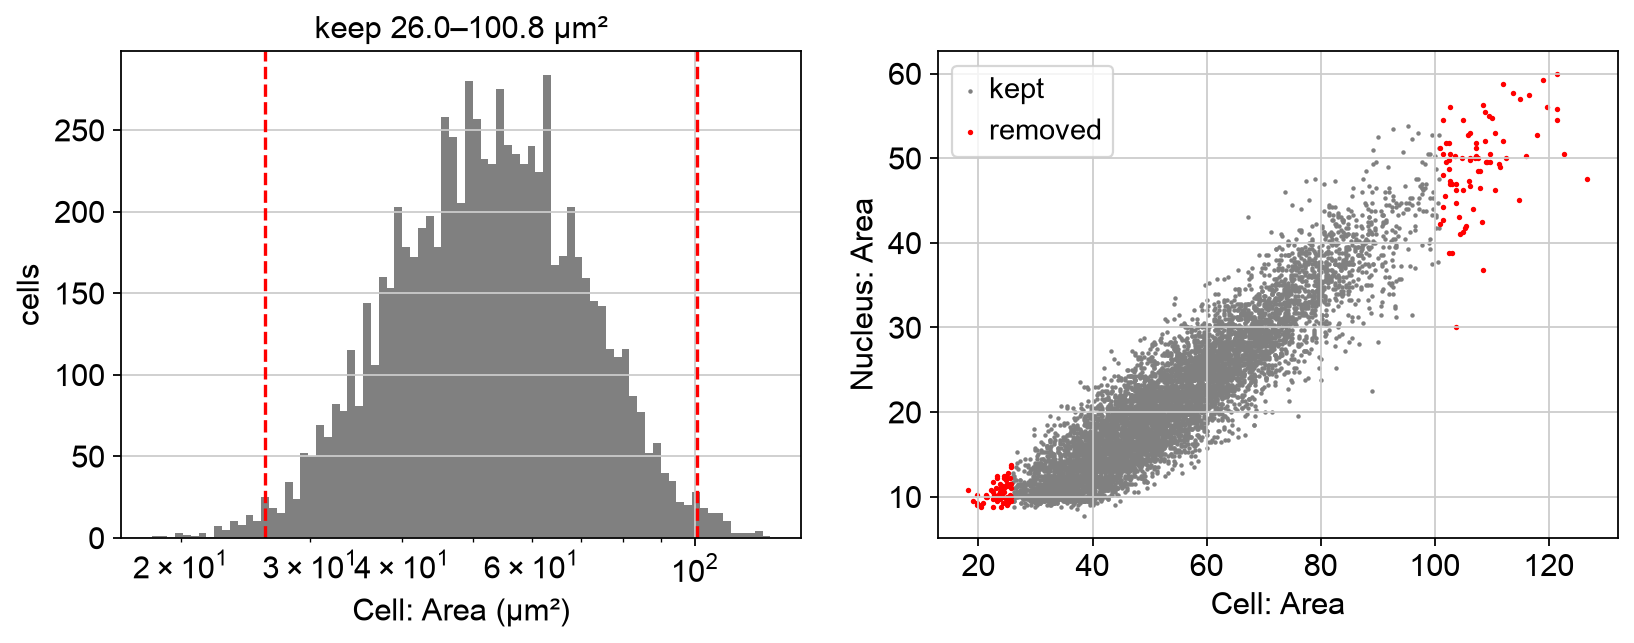

removed by cell size: 150


In [7]:
area = raw[AREA_COL]
area_lo, area_hi = area.quantile(AREA_QUANTILES)
fails["cell_area"] = ~area.between(area_lo, area_hi)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(area, bins=np.geomspace(area.min(), area.max(), 80), color="grey")
for v in (area_lo, area_hi):
    axes[0].axvline(v, color="red", ls="--")
axes[0].set_xscale("log")
axes[0].set_xlabel(f"{AREA_COL} (µm²)")
axes[0].set_ylabel("cells")
axes[0].set_title(f"keep {area_lo:.1f}–{area_hi:.1f} µm²")
bad = fails["cell_area"]
axes[1].scatter(area[~bad], raw.loc[~bad, "Nucleus: Area"], s=1, c="grey", rasterized=True, label="kept")
axes[1].scatter(area[bad], raw.loc[bad, "Nucleus: Area"], s=2, c="red", rasterized=True, label="removed")
axes[1].set_xlabel(AREA_COL)
axes[1].set_ylabel("Nucleus: Area")
axes[1].legend()
plt.show()
print(f"removed by cell size: {bad.sum()}")

### 3c. Nuclear stain (DAPI)
A real cell has a nucleus. Objects with almost no DAPI are usually debris, out-of-focus regions or
false detections.

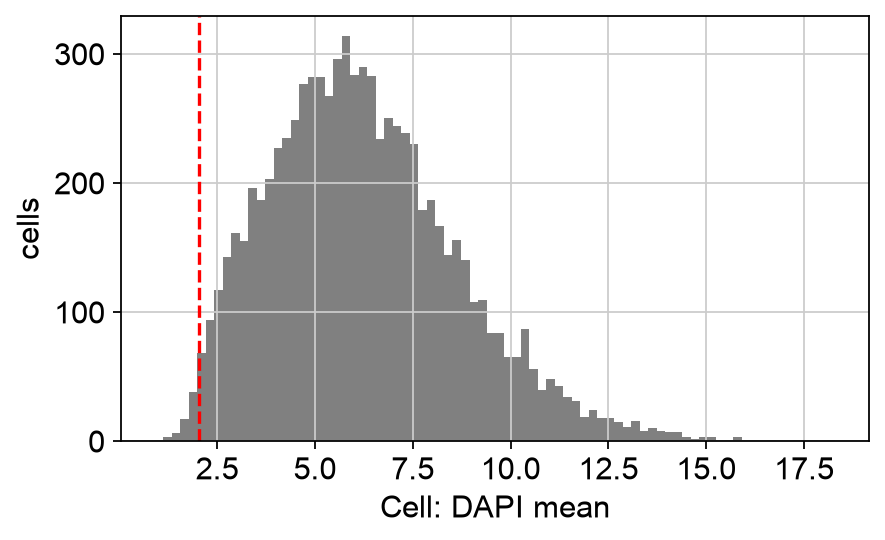

removed by low DAPI (< 2.03): 79


In [8]:
dapi = raw[all_means[NUCLEAR_MARKER]]
dapi_min = dapi.quantile(MIN_NUCLEAR_QUANTILE)
fails["low_nuclear"] = dapi < dapi_min

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(dapi, bins=80, color="grey")
ax.axvline(dapi_min, color="red", ls="--")
ax.set_xlabel(all_means[NUCLEAR_MARKER])
ax.set_ylabel("cells")
plt.show()
print(f"removed by low {NUCLEAR_MARKER} (< {dapi_min:.2f}): {fails['low_nuclear'].sum()}")

### 3d. Cells with no signal across the panel
In the IMC example, `sc.pp.filter_cells(min_genes=2)` drops cells with fewer than two markers above 0.
That doesn't transfer to Opal data: mean intensities are almost never exactly 0 (table below), so
the rule would remove nothing.

Instead a marker counts as **expressed** when it is above its background level (the `SIGNAL_QUANTILE`
of that marker in this assay), and cells expressing fewer than `MIN_MARKERS` panel markers are dropped.

,p62,CD147,LC3AB,Hpyl,MCT4,MCT1,HCAR1
fraction exactly 0,0.0,0.0,0.106,0.038,0.003,0.002,0.01


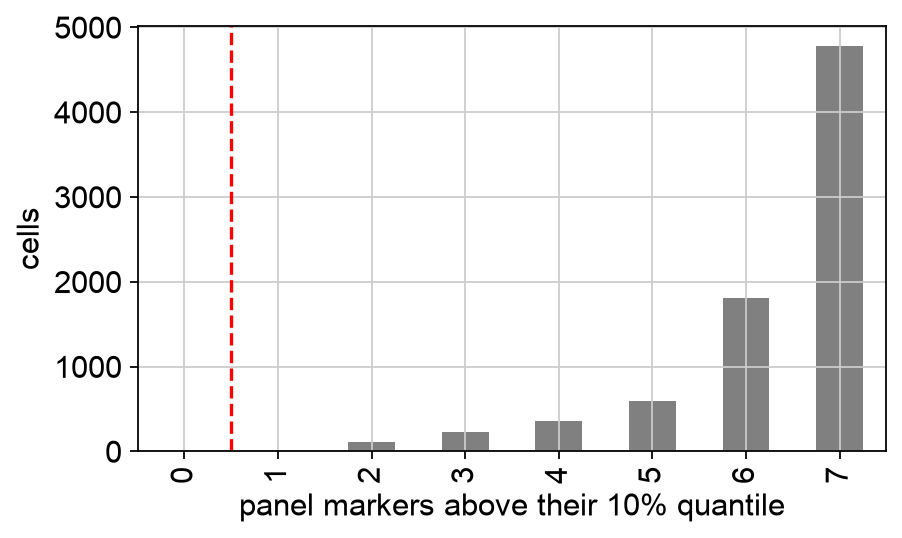

removed for no signal: 0


In [9]:
panel_df = raw[[cols[m] for m in panel]].set_axis(panel, axis=1)
display((panel_df == 0).mean().rename("fraction exactly 0").to_frame().T.round(3))

background = panel_df.quantile(SIGNAL_QUANTILE)
n_expressed = (panel_df > background).sum(axis=1)
fails["no_signal"] = n_expressed < MIN_MARKERS

fig, ax = plt.subplots(figsize=(6, 3.5))
n_expressed.value_counts().reindex(range(len(panel) + 1), fill_value=0).plot.bar(ax=ax, color="grey")
ax.axvline(MIN_MARKERS - 0.5, color="red", ls="--")
ax.set_xlabel(f"panel markers above their {SIGNAL_QUANTILE:.0%} quantile")
ax.set_ylabel("cells")
plt.show()
print(f"removed for no signal: {fails['no_signal'].sum()}")

### 3e. Autofluorescence (optional)
Very autofluorescent objects are often red blood cells, necrosis or bright tissue edges. The check is
off by default (`MAX_AF_QUANTILE = None`); look at the histogram and switch it on if there is a
distinct bright tail.

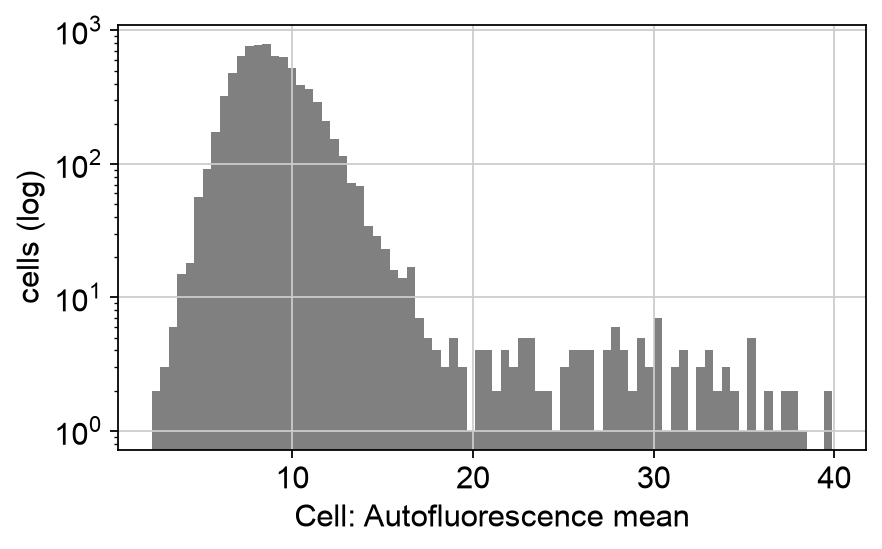

In [10]:
if AF_COL:
    af = raw[AF_COL]
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.hist(af, bins=80, color="grey", log=True)
    if MAX_AF_QUANTILE:
        fails["high_autofluorescence"] = af > af.quantile(MAX_AF_QUANTILE)
        ax.axvline(af.quantile(MAX_AF_QUANTILE), color="red", ls="--")
    ax.set_xlabel(AF_COL)
    ax.set_ylabel("cells (log)")
    plt.show()

### 3f. QC summary and where the removed cells are
Removed cells scattered evenly are expected. Removed cells **concentrated** along an edge, a fold or a
tear point to a tissue artefact; consider excluding that region (or the assay) rather than individual
cells.

,removed,% of cells
missing_values,0,0.0
cell_area,150,1.9
low_nuclear,79,1.0
no_signal,0,0.0
total removed,229,2.9
pass,7652,97.1


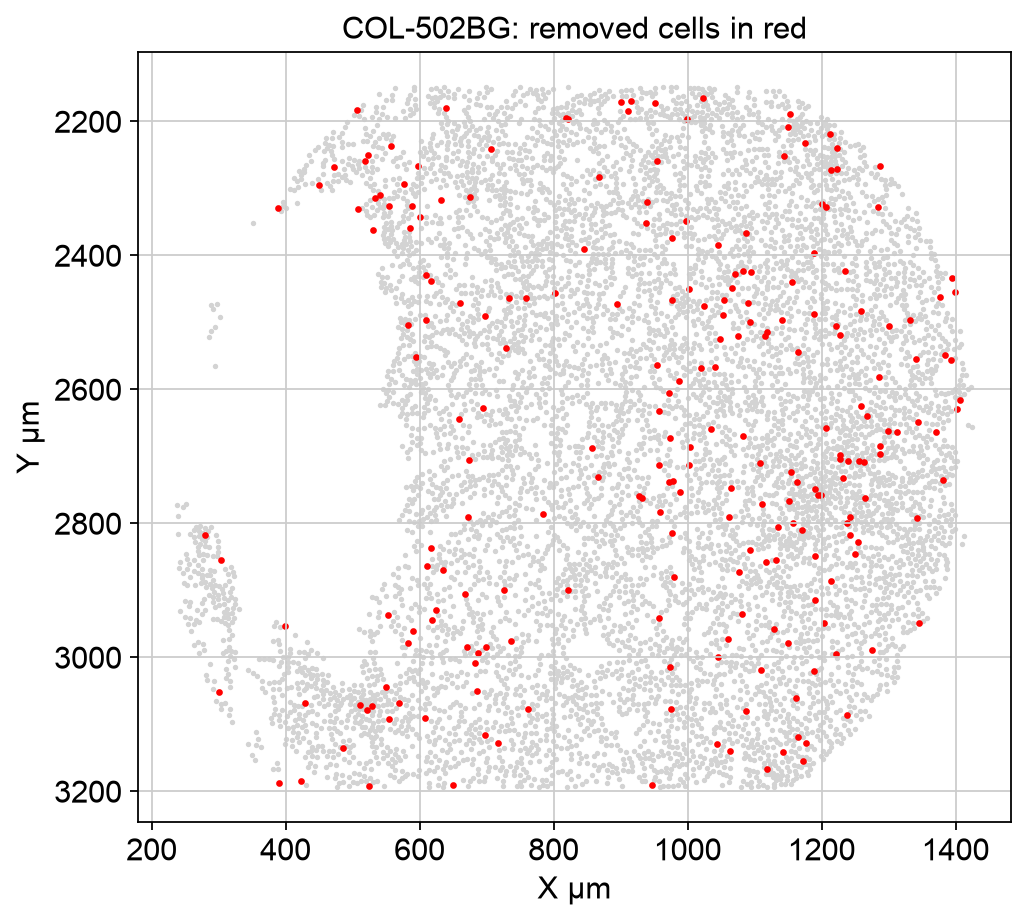

In [11]:
passing = ~fails.any(axis=1)
summary = fails.sum().rename("removed").to_frame()
summary.loc["total removed"] = (~passing).sum()
summary.loc["pass"] = passing.sum()
summary["% of cells"] = (100 * summary["removed"] / len(raw)).round(1)
display(summary)

fig, ax = plt.subplots(figsize=(7, 7))
xy = raw[[X_COL, Y_COL]].to_numpy()
tissue_scatter(ax, xy[passing], "lightgrey", f"{ASSAY}: removed cells in red")
ax.scatter(*xy[~passing].T, s=4, c="red", rasterized=True)
plt.show()

cells = raw[passing].reset_index(drop=True)

## 4. Spatial intensity maps

Each marker's whole-cell mean intensity (`log(x + 1)`, shared scale within a marker) on the tissue.
Check that staining patterns look biologically plausible and that there are no obvious artefacts
(bright edges, stripes, a saturated corner).

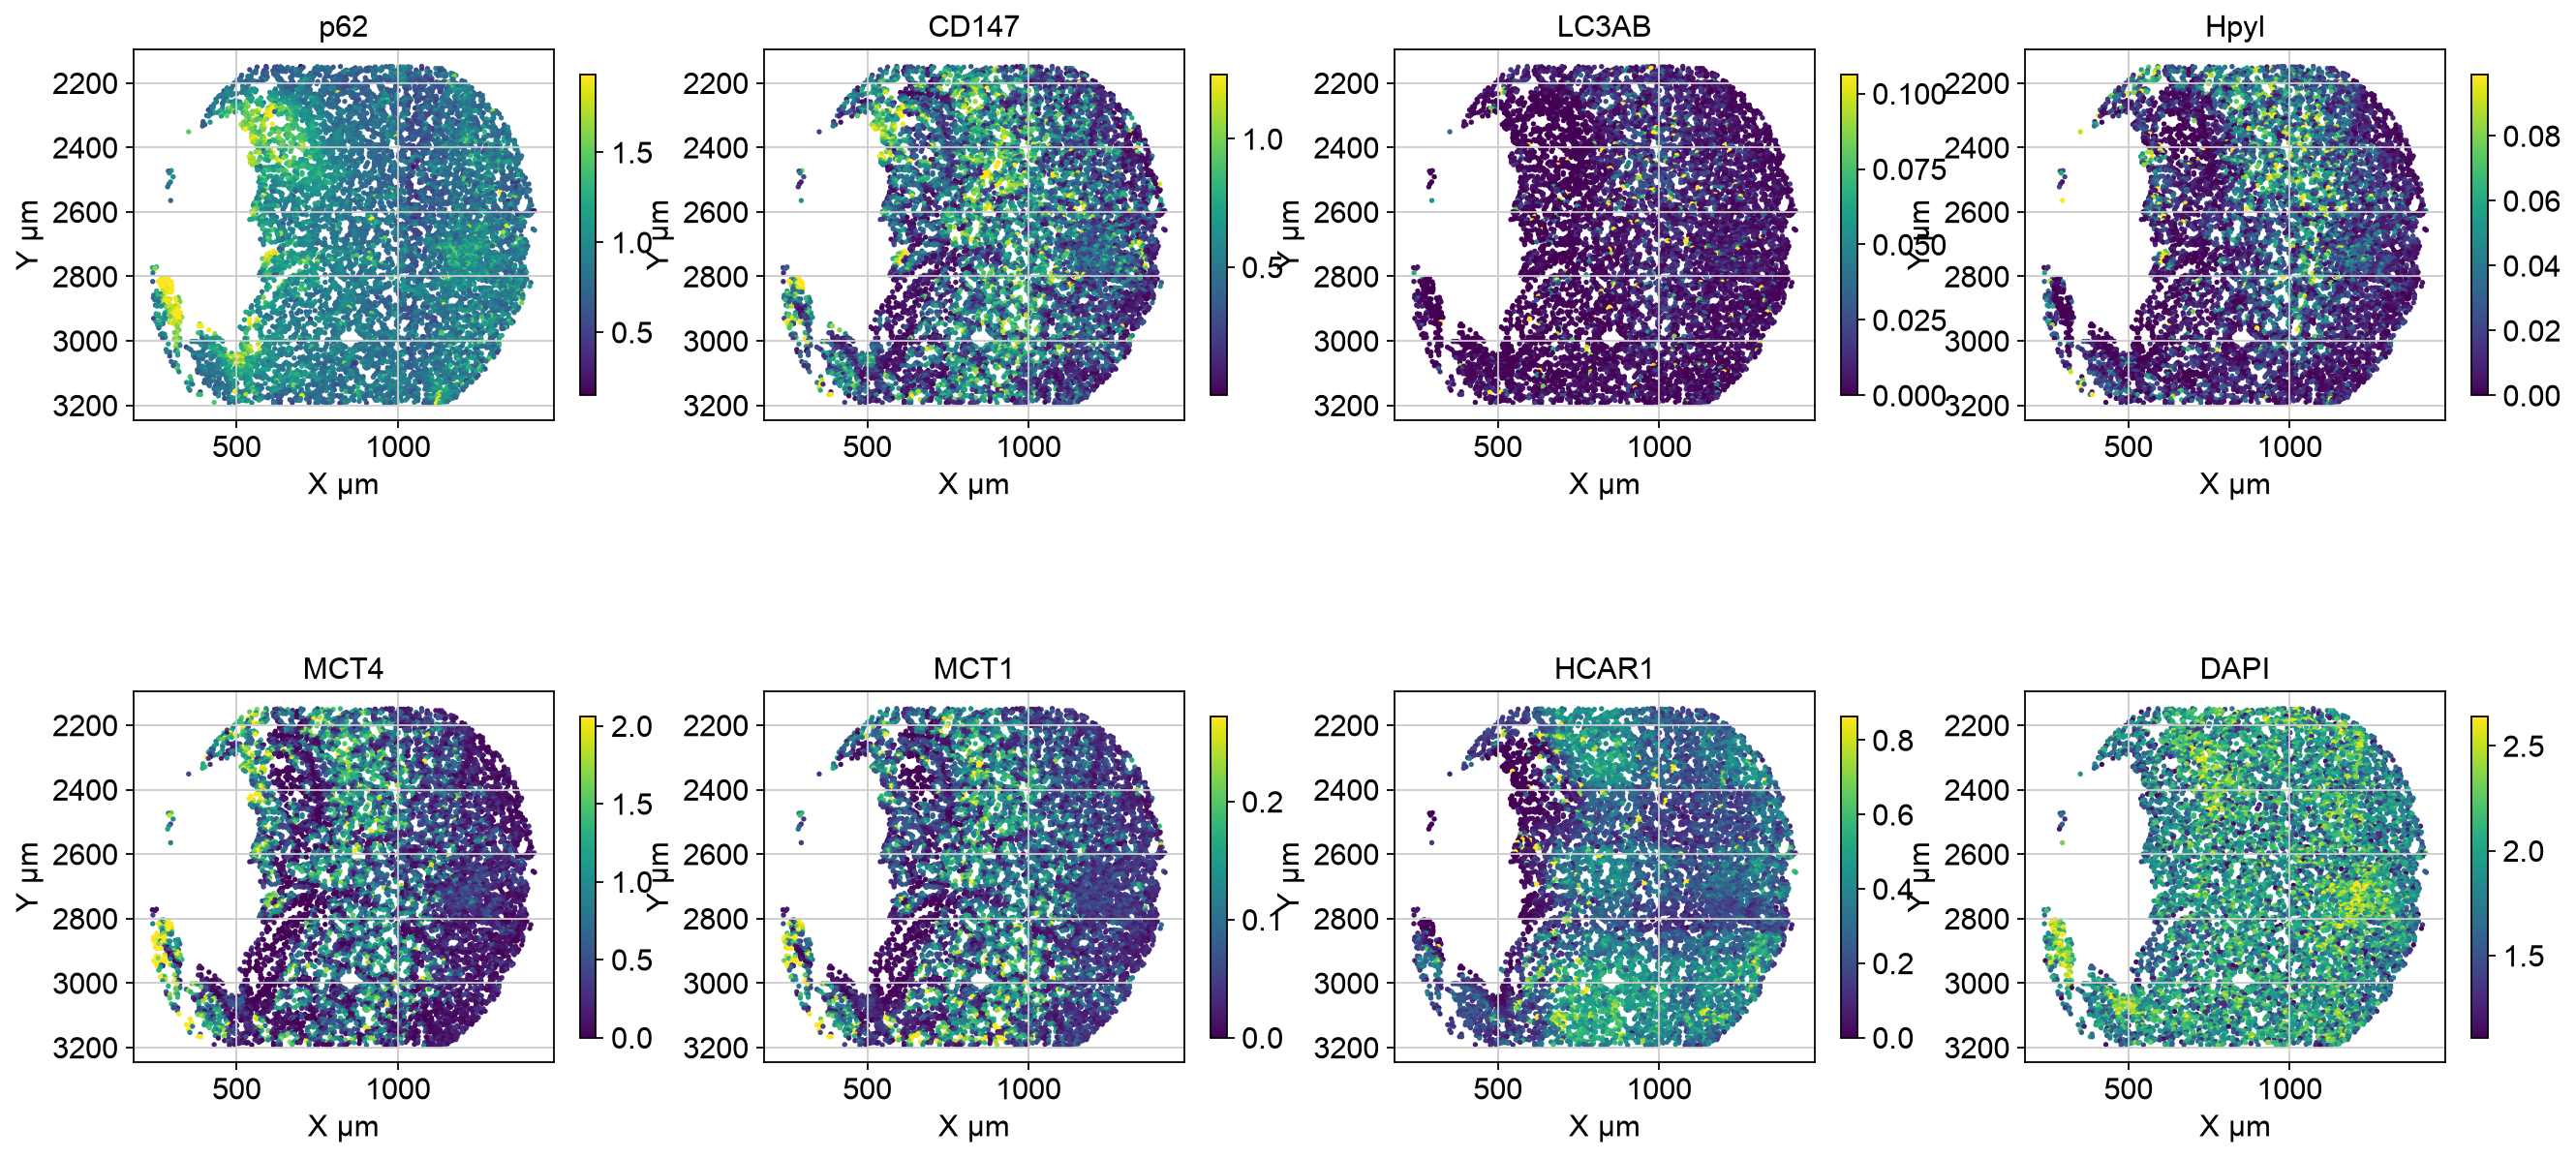

In [12]:
ncols = 4
nrows = -(-len(markers) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
xy = cells[[X_COL, Y_COL]].to_numpy()
for ax, m in zip(axes.flat, markers):
    v = np.log1p(cells[cols[m]])
    s = tissue_scatter(ax, xy, v, m, cmap="viridis", vmax=np.percentile(v, 99))
    fig.colorbar(s, ax=ax, shrink=0.6)
for ax in axes.flat[len(markers):]:
    ax.axis("off")
plt.show()

## 5. Build the AnnData object

- `X` – whole-cell mean intensity per marker (columns renamed to short marker names)
- `obs` – assay, morphology and other per-cell information
- `obsm['spatial']` – centroids in µm (used by squidpy and for tissue plots)
- `layers['raw']` – untouched intensities, so later transforms can always be undone

h5ad files can't store `/` in column names, so `Nucleus/Cell area ratio` becomes `Nucleus-Cell area ratio`.

In [13]:
SHAPE_KEYS = ("Area", "Perimeter", "Circularity", "caliper", "Eccentricity", "area ratio")
shape_cols = [c for c in cells.columns if "µm" in c or any(k in c for k in SHAPE_KEYS)]
obs = cells[["Parent"] + shape_cols].copy()
obs["Parent"] = obs["Parent"].astype("category")
obs["tma"] = pd.Categorical([TMA_FILE.stem] * len(obs))
obs.columns = obs.columns.str.replace("/", "-")
obs.index = (ASSAY + "_" + cells.index.astype(str)).values

adata = ad.AnnData(X=cells[list(cols.values())].to_numpy(np.float32), obs=obs,
                   var=pd.DataFrame(index=markers))
adata.obsm["spatial"] = cells[[X_COL, Y_COL]].to_numpy()
adata.layers["raw"] = adata.X.copy()
adata.uns["qc_params"] = {"area_quantiles": list(AREA_QUANTILES), "min_nuclear_quantile": MIN_NUCLEAR_QUANTILE,
                          "signal_quantile": SIGNAL_QUANTILE, "min_markers": MIN_MARKERS,
                          "max_af_quantile": MAX_AF_QUANTILE or 0}
adata

AnnData object with n_obs × n_vars = 7652 × 8
    obs: 'Parent', 'Centroid X µm', 'Centroid Y µm', 'Nucleus: Area', 'Nucleus: Perimeter', 'Nucleus: Circularity', 'Nucleus: Max caliper', 'Nucleus: Min caliper', 'Nucleus: Eccentricity', 'Cell: Area', 'Cell: Perimeter', 'Cell: Circularity', 'Cell: Max caliper', 'Cell: Min caliper', 'Cell: Eccentricity', 'Nucleus-Cell area ratio', 'tma'
    uns: 'qc_params'
    obsm: 'spatial'
    layers: None (.X), 'raw'

## 6. Clip very bright cells – choosing the level per marker

A few extremely bright cells (saturation, edge artefacts, over-staining) stretch a marker's range so
that after scaling most cells look identical and the outliers drive PCA and clustering. Clipping caps
each marker at a high quantile (the IMC example used 0.95 for all markers).

One global level is not always right. Read the histograms below (log counts; dashed lines = candidate
quantiles with their intensity, solid red = current choice):

- **thin, smoothly falling tail** → clip where the tail thins out (q0.99 is usually fine);
- **distinct bright population** (a second peak or a flat shelf) → put the cap *above* it, or don't
  clip that marker (`1`). Otherwise the whole population is squashed into one value. Check in QuPath
  whether it's real staining before keeping it;
- **a few isolated extreme cells** far beyond everything else → clip below them.

**Workflow:** look at the plot, edit `CLIP_MARKER` in the next cell, re-run it, repeat.

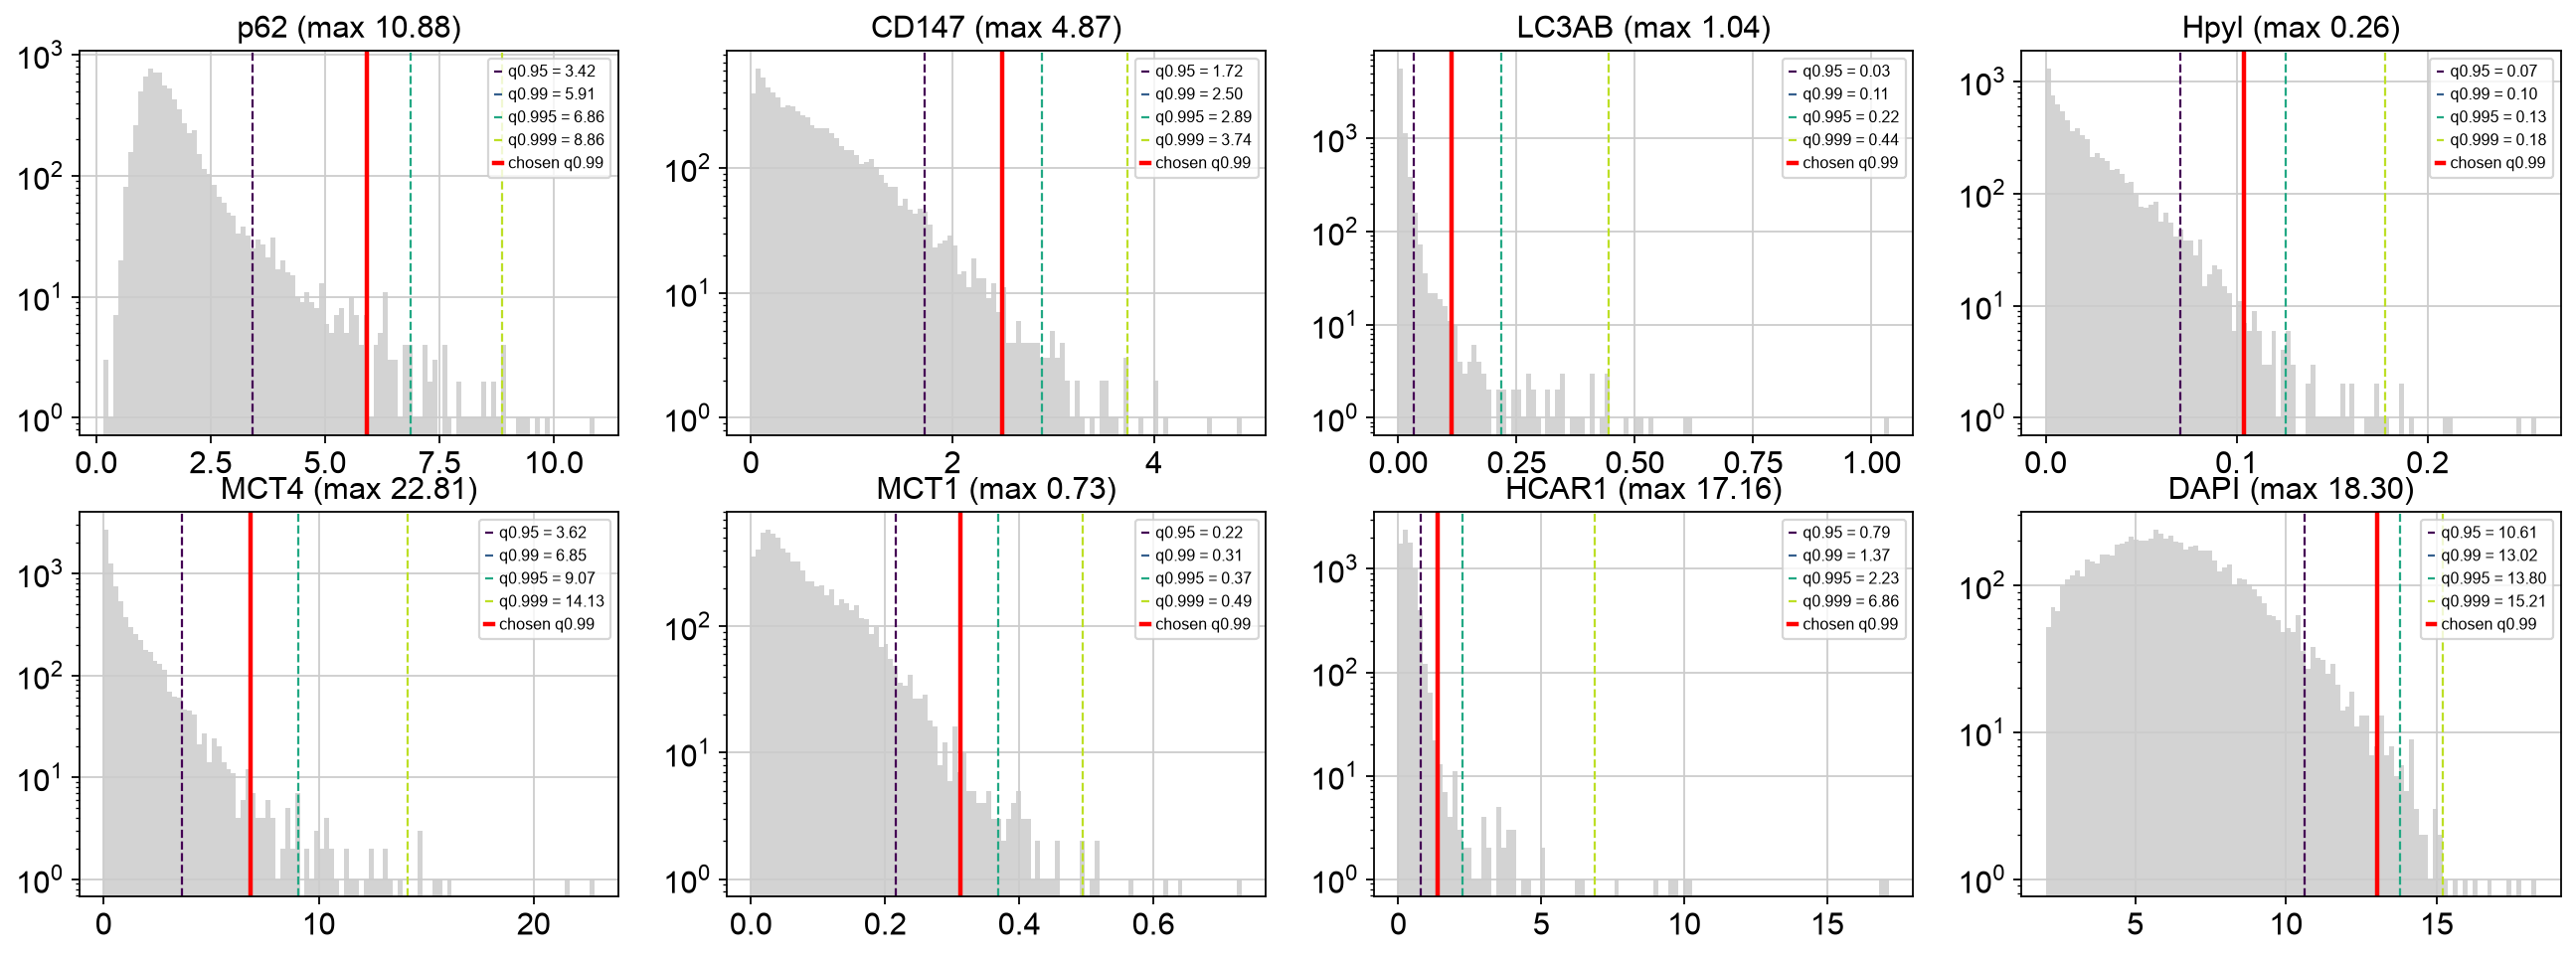

,q0.95,q0.99,q0.995,q0.999,max,chosen
p62,3.421,5.913,6.865,8.860,10.878000,0.99
CD147,1.722,2.496,2.886,3.737,4.868000,0.99
LC3AB,0.033,0.112,0.217,0.445,1.036000,0.99
Hpyl,0.070,0.104,0.125,0.178,0.257000,0.99
MCT4,3.625,6.847,9.070,14.129,22.806999,0.99
MCT1,0.215,0.313,0.369,0.494,0.731000,0.99
HCAR1,0.794,1.372,2.234,6.860,17.157000,0.99
DAPI,10.614,13.016,13.798,15.206,18.302000,0.99


In [14]:
CLIP_QUANTILE = 0.99                     # default for every marker (0 = no clipping at all)
CLIP_MARKER = {}                         # per-marker overrides, e.g. {"Hpyl": 0.9995, "LC3AB": 1}
CLIP_CANDIDATES = [0.95, 0.99, 0.995, 0.999]

df = adata.to_df(layer="raw")
clip_q = pd.Series({m: CLIP_MARKER.get(m, CLIP_QUANTILE) for m in markers})

ncols = 4
nrows = -(-len(markers) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), squeeze=False)
colors = plt.get_cmap("viridis")(np.linspace(0, 0.9, len(CLIP_CANDIDATES)))
for ax, m in zip(axes.flat, markers):
    ax.hist(df[m], bins=100, log=True, color="lightgrey")
    for q, c in zip(CLIP_CANDIDATES, colors):
        ax.axvline(df[m].quantile(q), color=c, ls="--", lw=1, label=f"q{q} = {df[m].quantile(q):.2f}")
    if 0 < clip_q[m] < 1:
        ax.axvline(df[m].quantile(clip_q[m]), color="red", lw=2, label=f"chosen q{clip_q[m]}")
    ax.set_title(f"{m} (max {df[m].max():.2f})")
    ax.legend(fontsize=7)
for ax in axes.flat[len(markers):]:
    ax.axis("off")
plt.show()

pd.DataFrame({f"q{q}": df.quantile(q) for q in CLIP_CANDIDATES}).assign(max=df.max(), chosen=clip_q).round(3)

Apply the chosen caps and compare each marker before (top, log counts) and after (bottom). After
clipping, a small spike at the cap is expected; a *large* spike means the cap cuts into real signal.

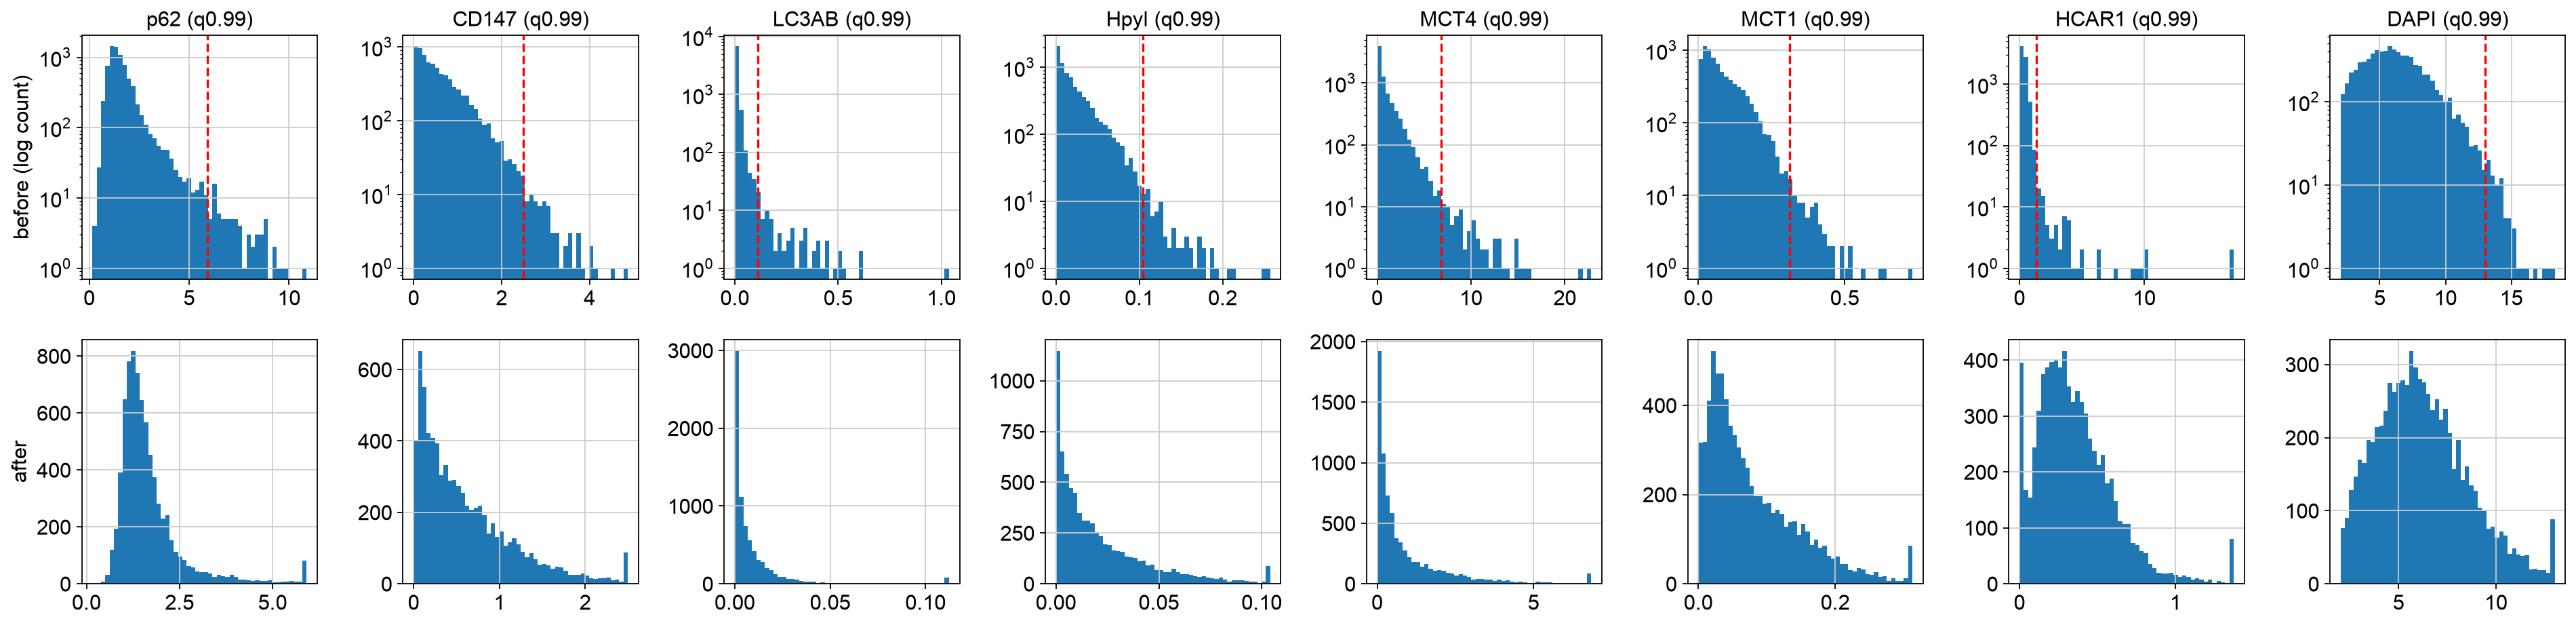

,cap,cells clipped
p62,5.913,77
CD147,2.496,77
LC3AB,0.112,77
Hpyl,0.104,77
MCT4,6.847,77
MCT1,0.313,76
HCAR1,1.372,77
DAPI,13.016,77


In [15]:
caps = pd.Series({m: df[m].quantile(q) if 0 < q < 1 else np.inf for m, q in clip_q.items()})
clipped = df.clip(lower=0, upper=caps, axis=1)

fig, axes = plt.subplots(2, len(markers), figsize=(3 * len(markers), 6), squeeze=False)
for j, m in enumerate(markers):
    axes[0, j].hist(df[m], bins=50, log=True)
    if np.isfinite(caps[m]):
        axes[0, j].axvline(caps[m], color="red", ls="--")
    axes[0, j].set_title(f"{m} (q{clip_q[m]})" if np.isfinite(caps[m]) else f"{m} (not clipped)")
    axes[1, j].hist(clipped[m], bins=50)
axes[0, 0].set_ylabel("before (log count)")
axes[1, 0].set_ylabel("after")
plt.tight_layout()
plt.show()

adata.X = clipped.to_numpy(np.float32)
adata.layers["clipped"] = adata.X.copy()
adata.uns["clip_values"] = caps[np.isfinite(caps)].to_dict()
adata.uns["qc_params"].update(clip_quantile=CLIP_QUANTILE, clip_marker=CLIP_MARKER)
pd.DataFrame({"cap": caps, "cells clipped": (df > caps).sum()}).round(3)

## 7. Transform

`log1p` compresses the remaining right skew so that differences between dim cells count as much as
differences between bright ones (as in `Skin_1_analysis`). The boxplots show the effect.

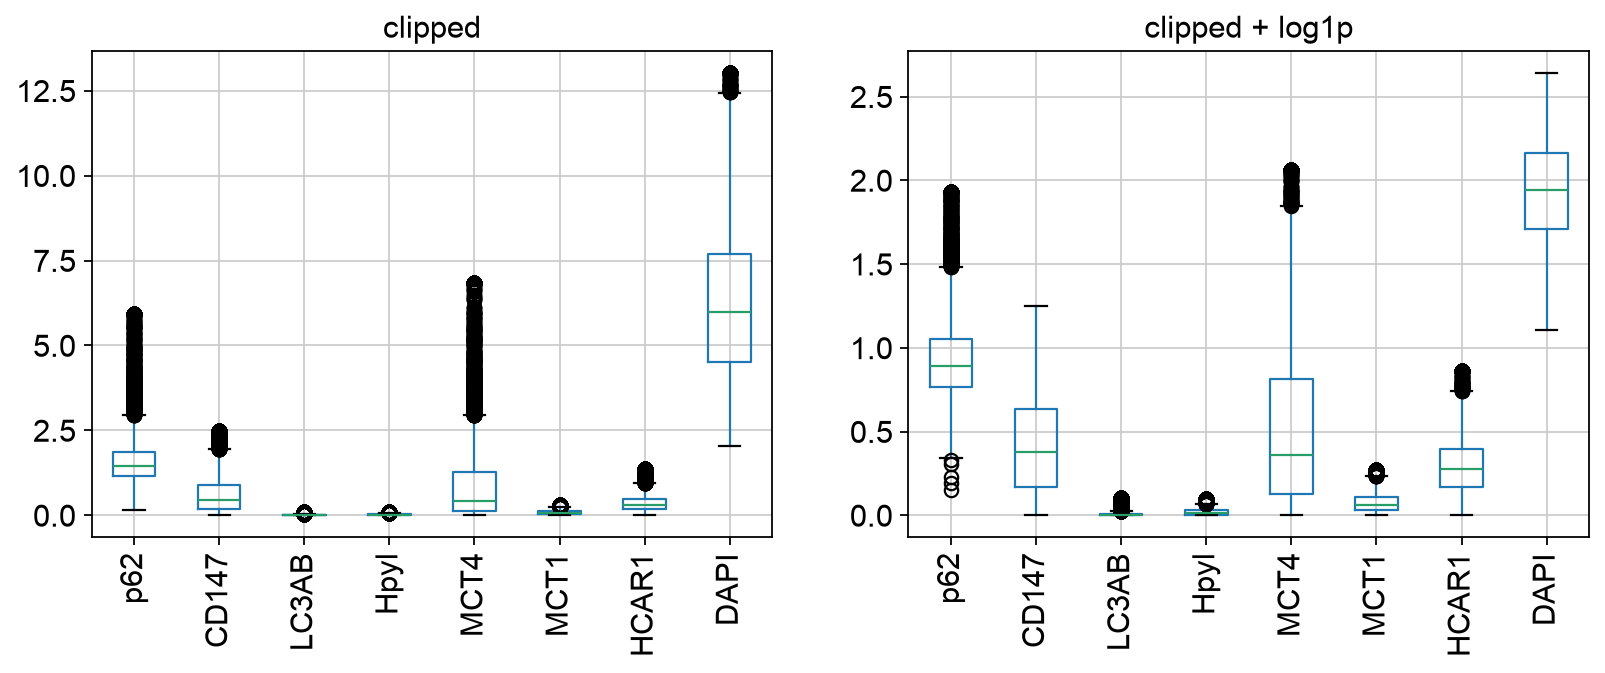

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
adata.to_df().boxplot(ax=axes[0], rot=90)
axes[0].set_title("clipped")
sc.pp.log1p(adata)
adata.to_df().boxplot(ax=axes[1], rot=90)
axes[1].set_title("clipped + log1p")
plt.show()

## 8. Cluster

Clustering uses the panel markers only (DAPI is left out: it marks every nucleus, not a cell type).

- `SCALE = True` z-scores each marker so a bright channel doesn't dominate the PCA just because of its
  intensity range (the original Skin_1 notebook didn't scale; the IMC example did).
- With only a handful of markers, a few PCs capture most of the variance – check the variance-ratio plot.
- `RESOLUTION` controls the number of clusters. Start around 0.3–1.0, then check the dotplot: every cluster
  should have a recognisable marker profile.

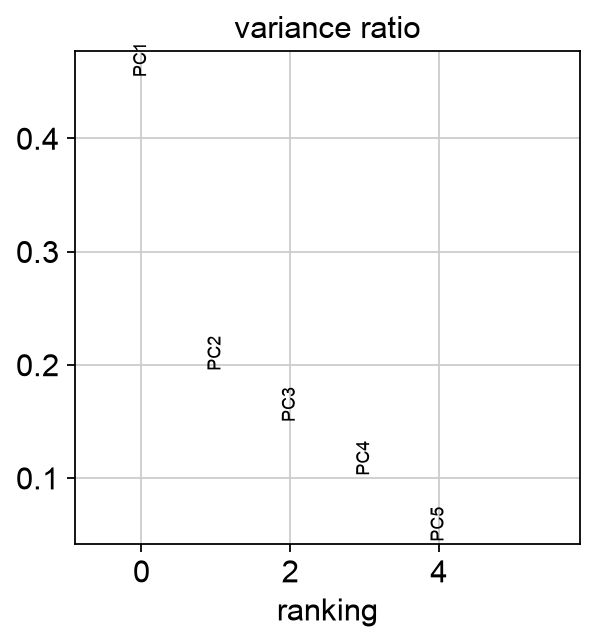

leiden,0,1,2,3,4,5,6,7,8,9,10
cells,1145,938,823,437,968,1051,282,899,407,647,55


In [17]:
clust = adata[:, panel].copy()
if SCALE:
    sc.pp.scale(clust, max_value=10)
n_pcs = min(N_PCS, clust.n_vars - 1)
sc.tl.pca(clust, n_comps=n_pcs, svd_solver="arpack")
sc.pl.pca_variance_ratio(clust, n_pcs=n_pcs)

sc.pp.neighbors(clust, n_neighbors=N_NEIGHBORS, n_pcs=n_pcs)
sc.tl.umap(clust)
sc.tl.leiden(clust, resolution=RESOLUTION, flavor="igraph", n_iterations=2)

# copy results back to the full object (which still has DAPI and the unscaled log1p values)
adata.obs["leiden"] = clust.obs["leiden"]
adata.obsm["X_pca"] = clust.obsm["X_pca"]
adata.obsm["X_umap"] = clust.obsm["X_umap"]
adata.uns["leiden_params"] = {"resolution": RESOLUTION, "n_neighbors": N_NEIGHBORS, "n_pcs": n_pcs, "scaled": SCALE}
adata.obs["leiden"].value_counts().sort_index().rename("cells").to_frame().T

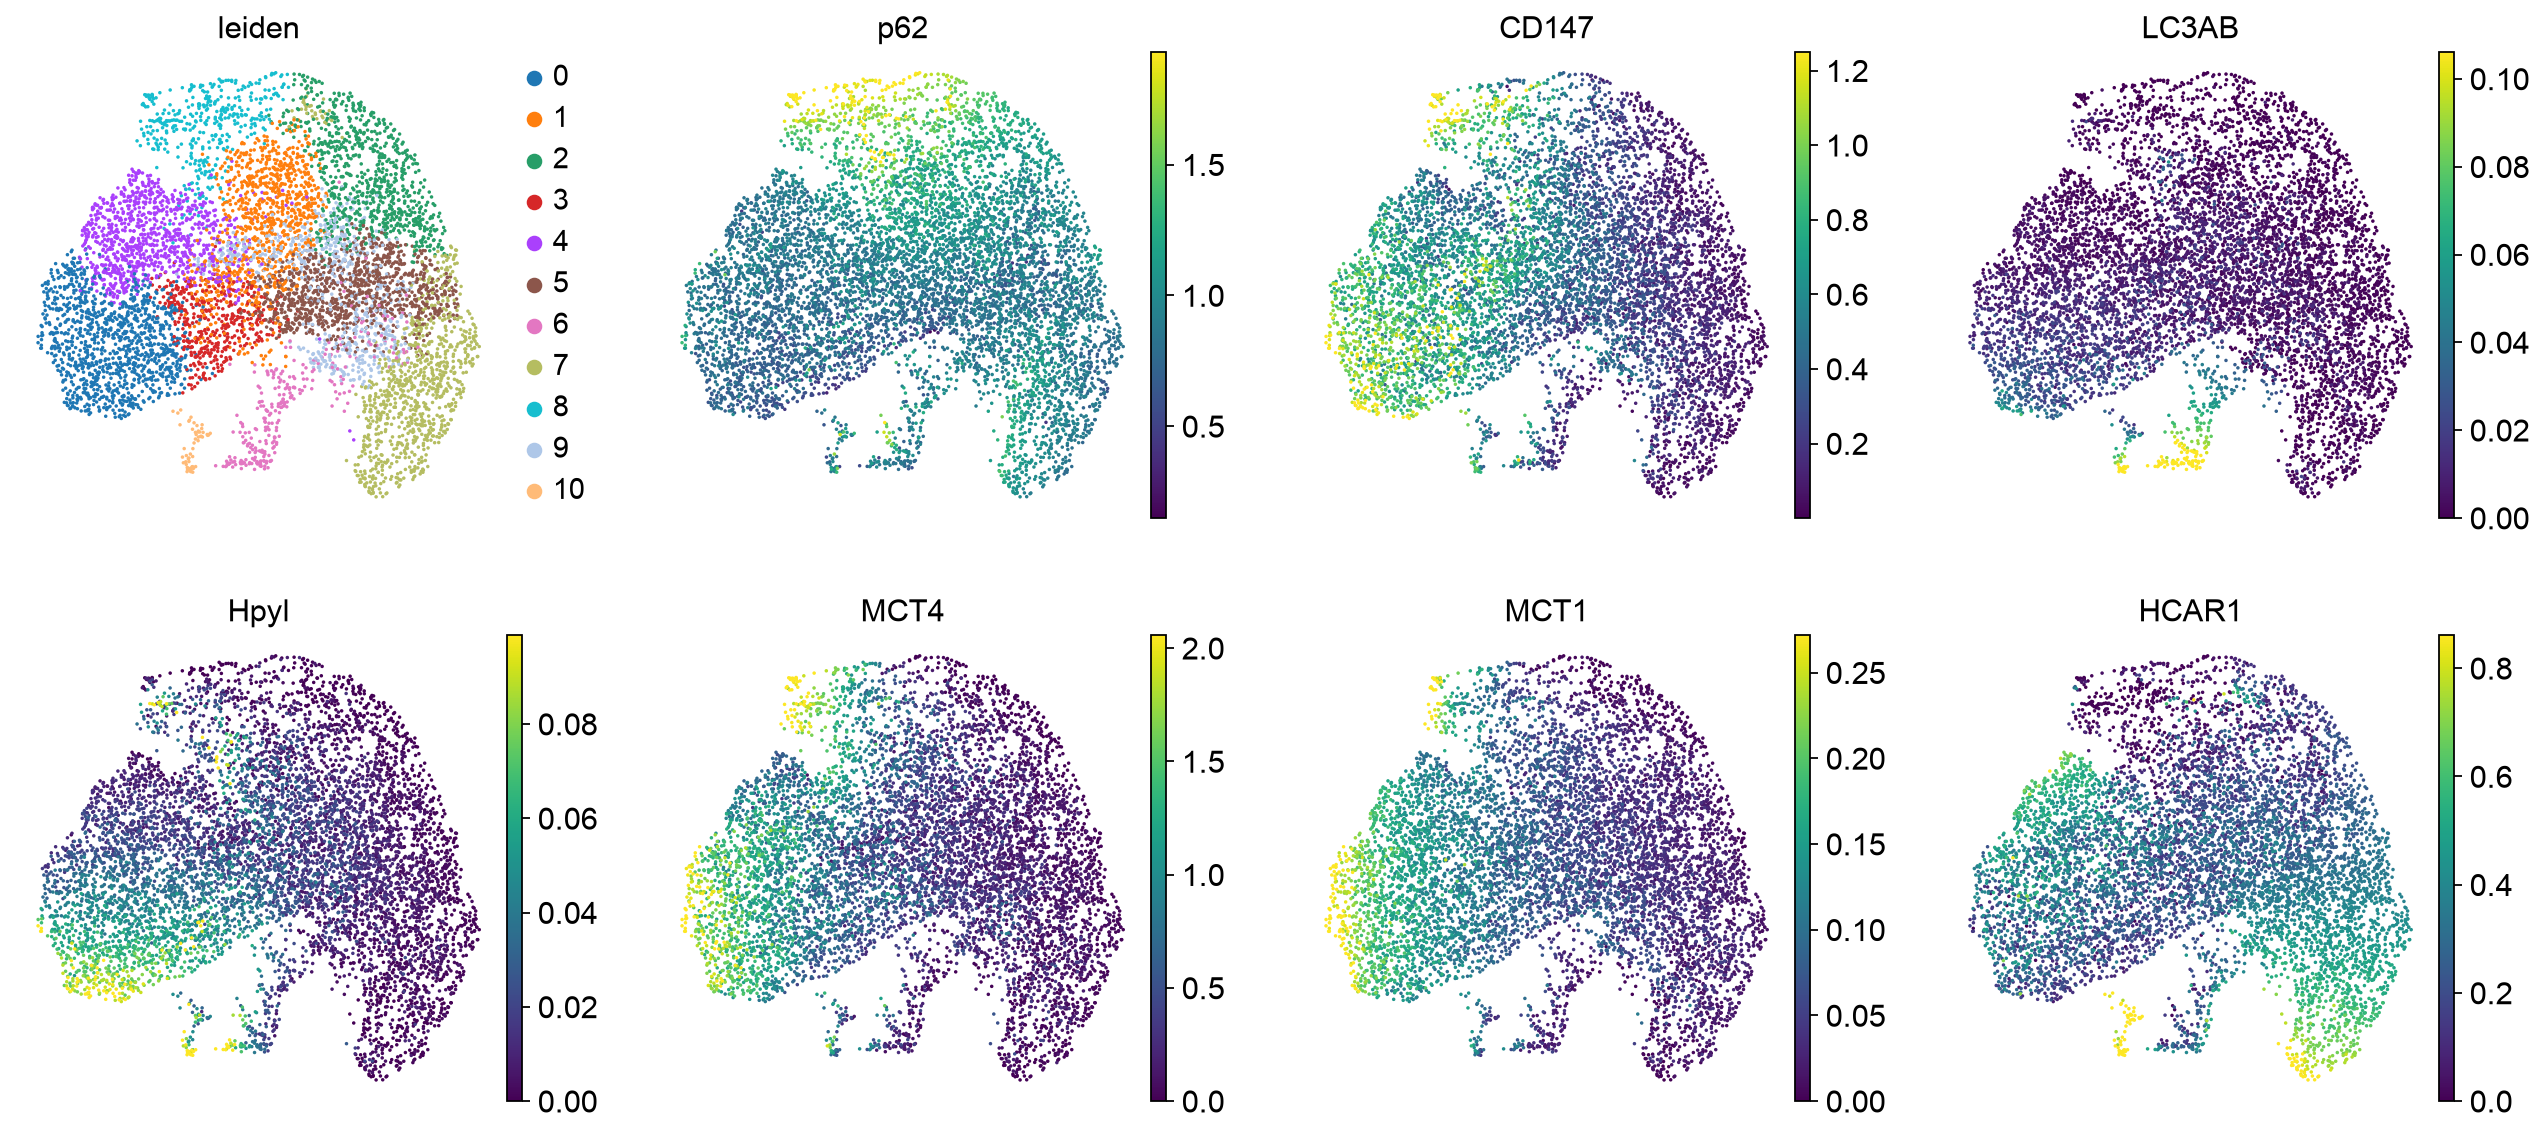

In [18]:
sc.pl.umap(adata, color=["leiden"] + panel, ncols=4, size=10, vmax="p99")

The dotplot shows mean (log1p) expression and the fraction of expressing cells per cluster; the
matrixplot scales each marker 0–1 across clusters, which makes each cluster's dominant markers easy
to spot. Use both to give clusters a biological interpretation.

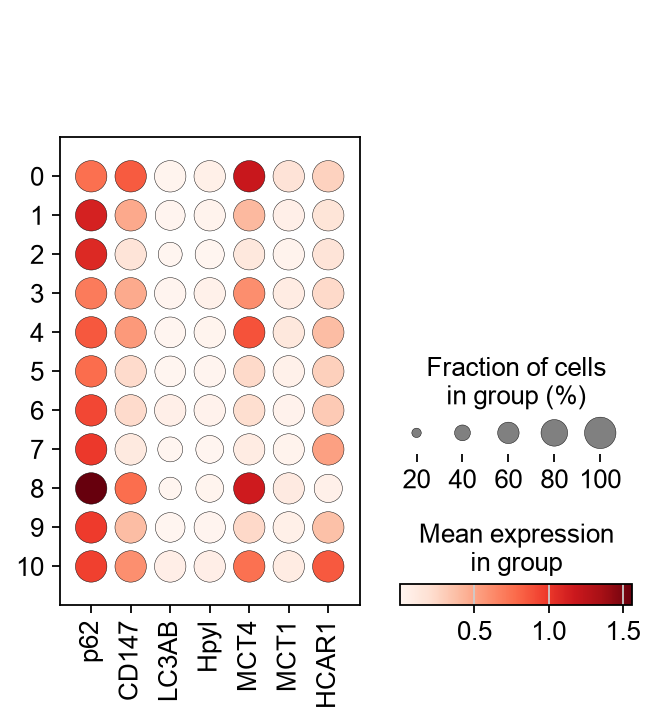

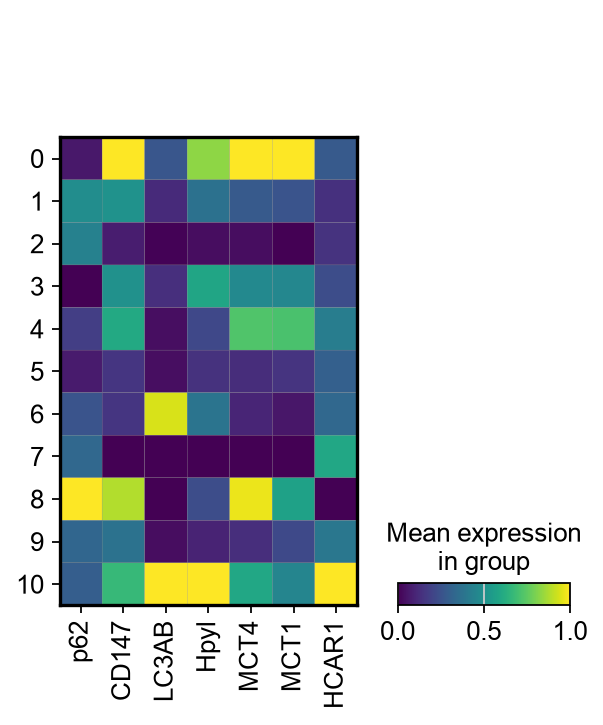

In [19]:
sc.pl.dotplot(adata, panel, groupby="leiden")
sc.pl.matrixplot(adata, panel, groupby="leiden", standard_scale="var", cmap="viridis")

## 9. Clusters on the tissue

Map the clusters back onto the assay. Coherent spatial regions (epithelium, stroma, immune
aggregates) are a good sign; salt-and-pepper patterns everywhere can mean the resolution is too high.

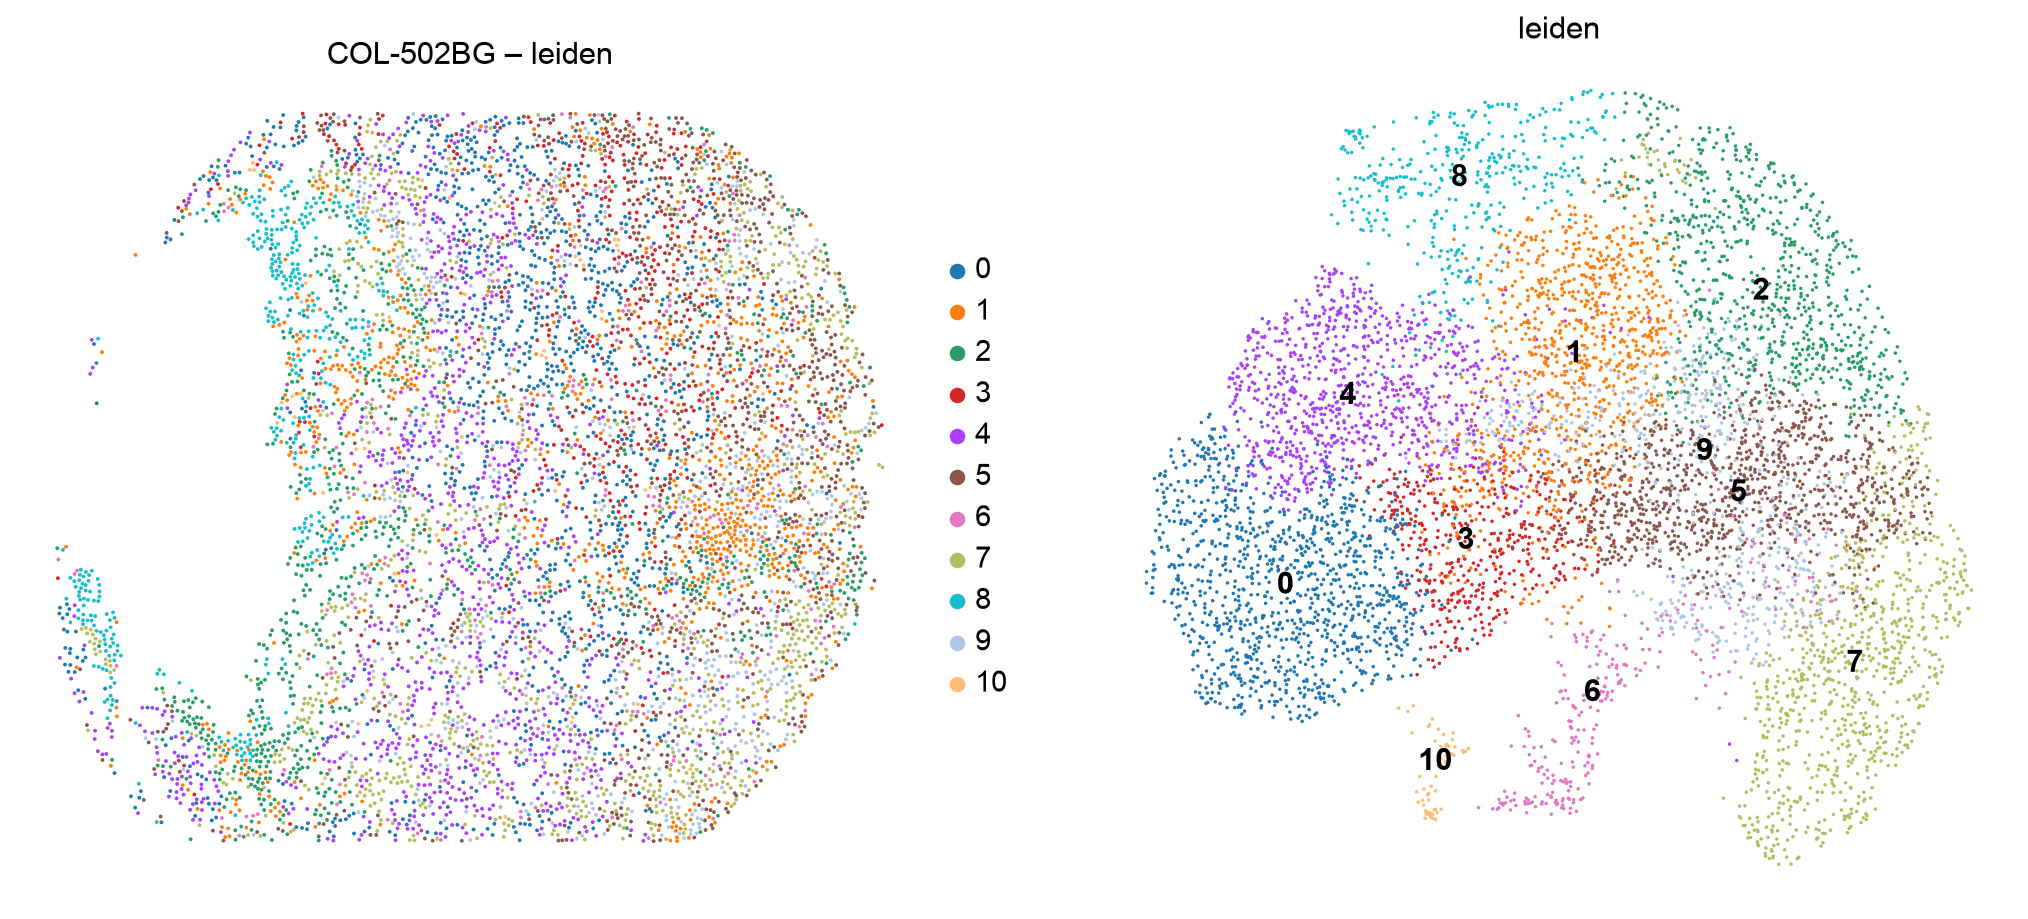

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sc.pl.embedding(adata, basis="spatial", color="leiden", size=12, ax=axes[0], show=False, title=f"{ASSAY} – leiden")
sc.pl.umap(adata, color="leiden", size=10, ax=axes[1], show=False, legend_loc="on data")
axes[0].invert_yaxis()
axes[0].set_aspect("equal")
plt.show()

### Neighbourhood enrichment
Which clusters sit next to each other more (red) or less (blue) often than expected by chance? A
Delaunay graph connects each cell to its touching neighbours; squidpy then compares observed neighbour
counts with random permutations of the labels (z-scores). With one assay there is a single tissue
piece, so no cross-assay edges can occur. When several assays are analysed together, build the graph
per assay (`library_key="Parent"`).

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/5d/x90dlmfs2_z95vh2_pz7z5p80000gp/T/ipykernel_54719/4019603822.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)


  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 1/1000 [00:03<50:37,  3.04s/]

 45%|████▍     | 447/1000 [00:03<00:02, 200.43/s]

 90%|█████████ | 902/1000 [00:03<00:00, 462.42/s]

100%|██████████| 1000/1000 [00:03<00:00, 306.57/s]

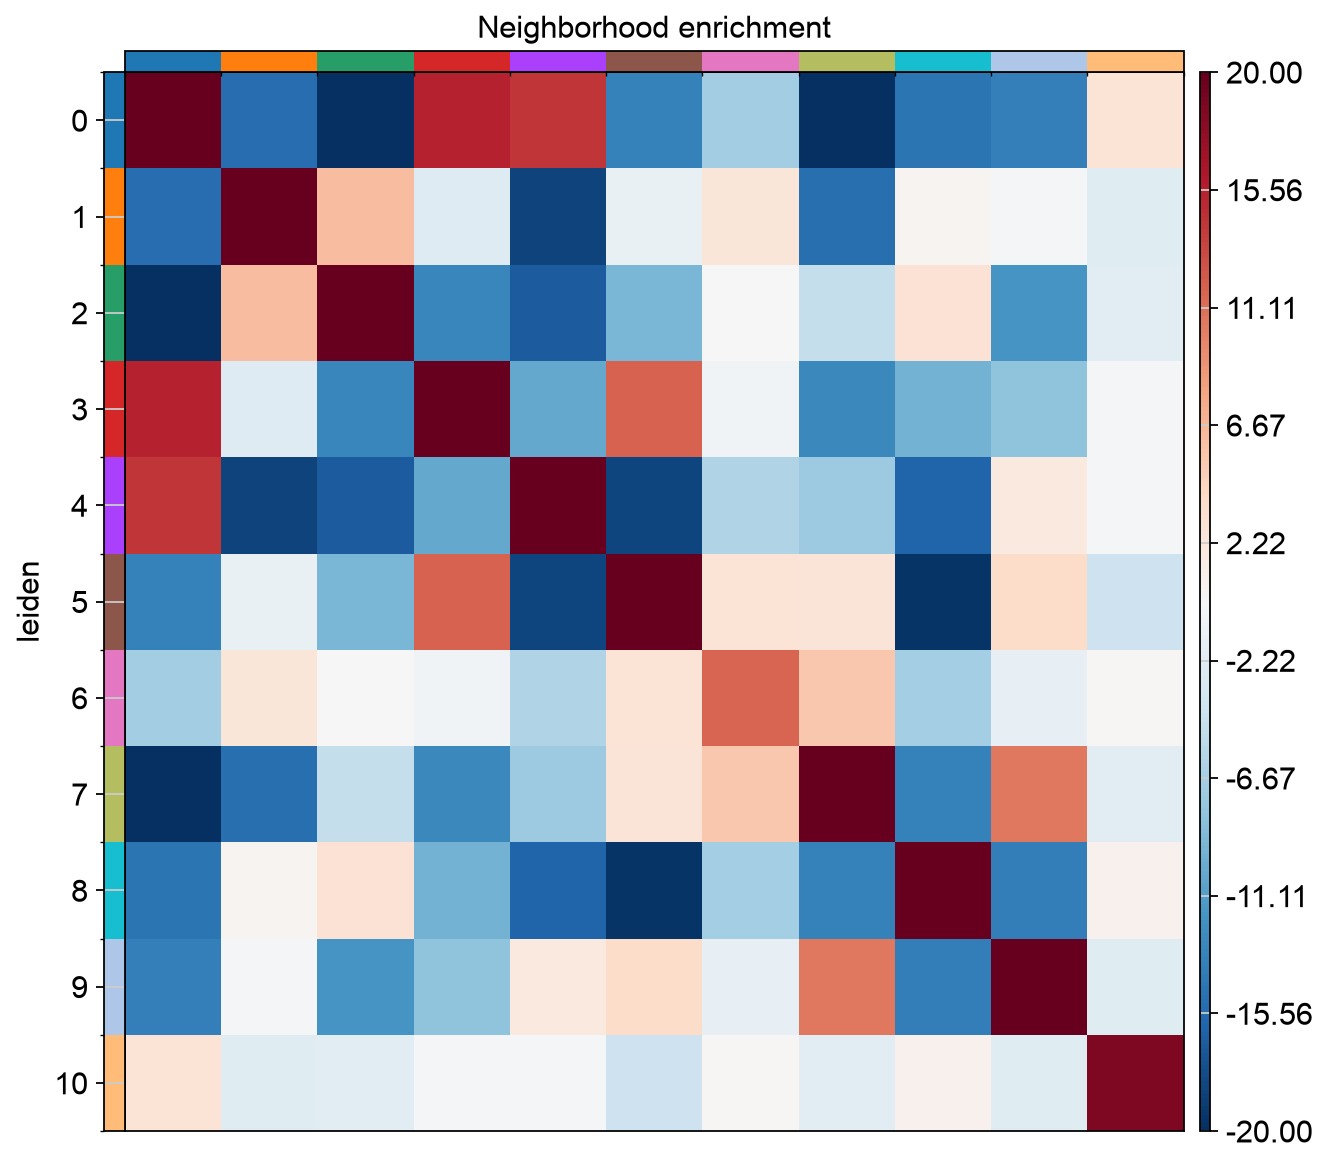

In [21]:
sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)
sq.gr.nhood_enrichment(adata, cluster_key="leiden", seed=0)
sq.pl.nhood_enrichment(adata, cluster_key="leiden", cmap="RdBu_r", vmin=-20, vmax=20)

## 10. Save

In [22]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
out_file = OUT_DIR / f"{TMA_FILE.stem}_{ASSAY}.h5ad"
adata.write_h5ad(out_file, compression="gzip")
out_file

PosixPath('results/assays/20260918_cell_detection_TMA1_COL-502BG.h5ad')

## Next: scaling up to all assays

- **Another assay:** change `ASSAY` (and `TMA_FILE`) in the parameters cell and re-run the notebook. Re-check
  the QC plots and the clip histograms; they differ between assays.
- **All assays together:** cluster labels from separate per-assay runs are *not* comparable (cluster 2 in one
  assay is unrelated to cluster 2 in another). To compare assays, process them jointly with the skill's script,
  which also adds the cross-assay batch checks (per-assay marker medians, cluster composition per assay):

```bash
# 1) fast QC loop: inspect figures/qc_*.png, pick clip levels
.venv/bin/python .claude/skills/analyzing-qupath-cells/scripts/run_pipeline.py \
    "Cell_dectection_results/*_cell_detection_TMA*.txt" --out results/tma_pipeline --group-by Parent --qc-only
# 2) full run with the chosen settings
.venv/bin/python .claude/skills/analyzing-qupath-cells/scripts/run_pipeline.py \
    "Cell_dectection_results/*_cell_detection_TMA*.txt" --out results/tma_pipeline --group-by Parent \
    --scale --resolution 0.5 --clip-marker Hpyl=0.9995 LC3AB=1
```

Note: the script computes QC quantiles per TMA file, this notebook per assay. If assays differ a lot
(watch `qc_marker_medians.png`), consider batch correction (e.g. Harmony, as in the IMC example;
`harmonypy` is installed) before joint clustering.